# Práctica— Análisis Descriptivo de Datos
### Business Analytics

| Campo | Detalle |
|---|---|
| **Estudiante** | Jeison Fabian Malagon Benavides
| **Programa** | Especialización en Analítica y Ciencia de Datos, Universidad de Cundinamarca |


## Preparación del entorno

Se importan las librerías: **pandas** y **numpy** para manipular y calcular, y **matplotlib** y **seaborn** para las visualizaciones. Se define un formato común de gráficos y una función para mostrar valores monetarios en millones de pesos (COP).

In [17]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12, "axes.labelsize": 10})
pd.options.display.float_format = "{:,.2f}".format
pd.set_option("display.max_columns", None)

AZUL, NARANJA, GRIS = "#2E74B5", "#E8A33D", "#7F7F7F"

def millones(x, pos=None):
    """Formatea un valor en pesos como millones: 1500000 -> '$2 M'."""
    return f"${x/1e6:,.1f} M" if abs(x) < 1e6 else f"${x/1e6:,.0f} M"

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


## Carga y exploración de los datos

**Paso 1. Se carga.** El archivo `ventas.csv`

In [18]:
RUTA_ARCHIVO = "ventas.csv"

if not os.path.exists(RUTA_ARCHIVO):
    try:
        from google.colab import files
        print("Archivo no encontrado en el repositorio. Sube 'ventas_ejemplo.csv' manualmente:")
        subido = files.upload()
        RUTA_ARCHIVO = list(subido.keys())[0]
    except ImportError:
        raise FileNotFoundError("No se encontró 'ventas_ejemplo.csv'. Colócalo en la misma carpeta que este notebook.")

df_raw = pd.read_csv(RUTA_ARCHIVO)
print(f"Datos cargados: {df_raw.shape[0]} filas x {df_raw.shape[1]} columnas.")
df_raw.head(10)

Datos cargados: 426 filas x 6 columnas.


,Fecha,Region,Producto,Vendedor,Unidades,PrecioUnitario
0,2026-06-01,Bogotá,Webcam,Luis Peña,3.00,95000
1,2026-01-15,Barranquilla,Webcam,Luis Peña,2.00,115000
2,2025-06-23,Cali,Mouse,Diana Gómez,3.00,60000
3,2026-04-16,Barranquilla,Monitor,Ana Torres,3.00,660000
4,2025-10-24,Cali,Webcam,Ana Torres,8.00,85000
5,2026-04-01,Bucaramanga,Impresora,Diana Gómez,15.00,500000
6,2025-10-23,Medellín,Mouse,Ana Torres,3.00,50000
7,2026-06-23,Barranquilla,Teclado,Sofía Reyes,9.00,120000
8,2025-12-13,Cali,Monitor,Sofía Reyes,9.00,640000
9,2025-12-08,Bogotá,Mouse,Diana Gómez,4.00,50000


**Paso 2. Exploración inicial.** Antes de analizar se revisa la estructura: tipos de dato, valores nulos, filas duplicadas, valores atípicos evidentes y categorías de las variables de texto. Esta revisión justifica las decisiones de limpieza del siguiente apartado.

In [19]:
print("Estructura del conjunto de datos:")
df_raw.info()

print("\nValores nulos por columna:")
print(df_raw.isnull().sum())

print(f"\nFilas duplicadas exactas: {df_raw.duplicated().sum()}")
print(f"Precios unitarios negativos: {(df_raw['PrecioUnitario'] < 0).sum()}")
print(f"Rango de fechas (texto): {df_raw['Fecha'].min()}  a  {df_raw['Fecha'].max()}")

print("\nCategorías en 'Region' (nótense las inconsistencias de mayúsculas y espacios):")
print(sorted(df_raw["Region"].unique()))
print("\nCategorías en 'Vendedor':")
print(sorted(df_raw["Vendedor"].unique()))
print("\nCategorías en 'Producto':")
print(sorted(df_raw["Producto"].unique()))

Estructura del conjunto de datos:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 426 entries, 0 to 425
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Fecha           426 non-null    object 
 1   Region          426 non-null    object 
 2   Producto        426 non-null    object 
 3   Vendedor        426 non-null    object 
 4   Unidades        420 non-null    float64
 5   PrecioUnitario  426 non-null    int64  
dtypes: float64(1), int64(1), object(4)
memory usage: 20.1+ KB

Valores nulos por columna:
Fecha             0
Region            0
Producto          0
Vendedor          0
Unidades          6
PrecioUnitario    0
dtype: int64

Filas duplicadas exactas: 6
Precios unitarios negativos: 4
Rango de fechas (texto): 2025-01-02  a  2026-06-28

Categorías en 'Region' (nótense las inconsistencias de mayúsculas y espacios):
['  barranquilla  ', '  bucaramanga  ', '  medellín  ', '  pereira  ', 'BARRANQUILLA', 

**Diagnóstico de la exploración**

| Hallazgo | Evidencia | Implicación |
|---|---|---|
| Filas duplicadas | 6 registros repetidos | Inflarían las ventas: se eliminan |
| Nulos en `Unidades` | 6 registros sin cantidad | Sin cantidad no se puede calcular el ingreso: se eliminan (1,4 % de los datos) |
| Precios negativos | 4 registros | Error de captura de signo: se corrigen con el valor absoluto |
| Texto inconsistente | Mayúsculas y espacios en `Region`, `Vendedor` y `Producto` | Una misma categoría aparecería varias veces: se estandariza |
| `Fecha` como texto | No es de tipo fecha | Se convierte para analizar el tiempo |

Son las mismas decisiones documentadas en el taller de obtención de datos (ETL); aquí se aplican de nuevo para que el análisis parta de datos confiables y el notebook sea reproducible.

## Limpieza y organización de los datos

Se aplican, en orden, las transformaciones del diagnóstico y se crean variables derivadas que facilitan el análisis:

- `Anio`, `Mes`, `Trimestre` y `Periodo` (año-mes) para análisis temporales.
- `VentaTotal` = `Unidades` × `PrecioUnitario`, el ingreso de cada transacción.

In [20]:
df = df_raw.copy()

# 1) Eliminar duplicados exactos
antes = len(df)
df = df.drop_duplicates()
print(f"Duplicados eliminados: {antes - len(df)}")

# 2) Estandarizar texto: sin espacios sobrantes y en formato 'Título'
for col in ["Region", "Vendedor", "Producto"]:
    df[col] = df[col].astype(str).str.strip().str.title()

# 3) Convertir 'Fecha' a datetime y derivar variables de tiempo
df["Fecha"] = pd.to_datetime(df["Fecha"], errors="coerce")
df["Anio"] = df["Fecha"].dt.year
df["Mes"] = df["Fecha"].dt.month
df["Trimestre"] = df["Fecha"].dt.to_period("Q").astype(str)
df["Periodo"] = df["Fecha"].dt.to_period("M").astype(str)

# 4) Eliminar filas sin 'Unidades' (1,4 % de los datos)
antes = len(df)
df = df.dropna(subset=["Unidades"])
df["Unidades"] = df["Unidades"].astype(int)
print(f"Filas eliminadas por 'Unidades' nula: {antes - len(df)}")

# 5) Corregir precios negativos (error de signo)
print(f"Precios negativos corregidos: {(df['PrecioUnitario'] < 0).sum()}")
df["PrecioUnitario"] = df["PrecioUnitario"].abs()

# 6) Ingreso por transacción
df["VentaTotal"] = df["Unidades"] * df["PrecioUnitario"]

df = df[["Fecha", "Anio", "Mes", "Trimestre", "Periodo", "Region", "Producto", "Vendedor", "Unidades", "PrecioUnitario", "VentaTotal"]]
df = df.sort_values("Fecha").reset_index(drop=True)
print(f"\nLimpieza completada: {df.shape[0]} filas x {df.shape[1]} columnas.")
df.head(8)

Duplicados eliminados: 6
Filas eliminadas por 'Unidades' nula: 6
Precios negativos corregidos: 4

Limpieza completada: 414 filas x 11 columnas.


,Fecha,Anio,Mes,Trimestre,Periodo,Region,Producto,Vendedor,Unidades,PrecioUnitario,VentaTotal
0,2025-01-02,2025,1,2025Q1,2025-01,Barranquilla,Mouse,Luis Peña,11,50000,550000
1,2025-01-03,2025,1,2025Q1,2025-01,Barranquilla,Audífonos,Carlos Ruiz,14,160000,2240000
2,2025-01-05,2025,1,2025Q1,2025-01,Bucaramanga,Webcam,Jorge Salas,13,105000,1365000
3,2025-01-08,2025,1,2025Q1,2025-01,Bogotá,Monitor,Sofía Reyes,3,650000,1950000
4,2025-01-09,2025,1,2025Q1,2025-01,Cali,Audífonos,Jorge Salas,4,140000,560000
5,2025-01-10,2025,1,2025Q1,2025-01,Pereira,Mouse,Jorge Salas,9,70000,630000
6,2025-01-11,2025,1,2025Q1,2025-01,Bucaramanga,Monitor,Luis Peña,14,650000,9100000
7,2025-01-12,2025,1,2025Q1,2025-01,Bucaramanga,Impresora,Diana Gómez,8,500000,4000000


**Validación posterior a la limpieza.** Se comprueba que los problemas detectados ya no existen y se compara el antes y el después.

In [21]:
validacion = pd.DataFrame({
    "Antes (crudo)": [len(df_raw), df_raw.isnull().sum().sum(), df_raw.duplicated().sum(), (df_raw["PrecioUnitario"] < 0).sum(), df_raw["Region"].nunique()],
    "Después (limpio)": [len(df), df.isnull().sum().sum(), df.duplicated().sum(), (df["PrecioUnitario"] < 0).sum(), df["Region"].nunique()],
}, index=["Filas", "Valores nulos", "Duplicados", "Precios negativos", "Regiones distintas"])
display(validacion)

print("Regiones:", sorted(df["Region"].unique()))
print("Productos:", sorted(df["Producto"].unique()))
print("Vendedores:", sorted(df["Vendedor"].unique()))
print(f"Periodo analizado: {df['Fecha'].min().date()} a {df['Fecha'].max().date()}")

# Se guarda el conjunto limpio como insumo reutilizable
df.to_csv("ventas_limpias.csv", index=False)

,Antes (crudo),Después (limpio)
Filas,426,414
Valores nulos,6,0
Duplicados,6,0
Precios negativos,4,0
Regiones distintas,16,6


Regiones: ['Barranquilla', 'Bogotá', 'Bucaramanga', 'Cali', 'Medellín', 'Pereira']
Productos: ['Audífonos', 'Impresora', 'Laptop', 'Monitor', 'Mouse', 'Teclado', 'Webcam']
Vendedores: ['Ana Torres', 'Carlos Ruiz', 'Diana Gómez', 'Jorge Salas', 'Luis Peña', 'Sofía Reyes']
Periodo analizado: 2025-01-02 a 2026-06-28


La limpieza dejó **414 transacciones** sin nulos ni duplicados, y **6 regiones** (en lugar de las variantes de escritura del archivo crudo). El análisis siguiente usa este conjunto.

##  Estadísticas descriptivas

### Variables numéricas: tendencia central, dispersión y forma

Para `Unidades`, `PrecioUnitario` y `VentaTotal` se calcula un resumen completo. El **coeficiente de variación** (desviación estándar ÷ media) permite comparar la dispersión de variables con escalas distintas; la **asimetría** indica si hay cola hacia valores altos (positiva) o bajos (negativa), y la **curtosis**, si la distribución es más plana o más puntiaguda que la normal.

In [22]:
def resumen_numerico(s):
    return pd.Series({
        "Conteo": s.count(), "Media": s.mean(), "Mediana": s.median(), "Moda": s.mode().iloc[0],
        "Desviación estándar": s.std(), "Coeficiente de variación": s.std() / s.mean(),
        "Mínimo": s.min(), "Q1 (25 %)": s.quantile(0.25), "Q3 (75 %)": s.quantile(0.75), "Máximo": s.max(),
        "Rango": s.max() - s.min(), "IQR": s.quantile(0.75) - s.quantile(0.25),
        "Asimetría": s.skew(), "Curtosis": s.kurt(),
    })

tabla_num = df[["Unidades", "PrecioUnitario", "VentaTotal"]].apply(resumen_numerico)
tabla_num

,Unidades,PrecioUnitario,VentaTotal
Conteo,414.00,414.00,414.00
Media,7.57,"622,234.30","4,631,292.27"
Mediana,7.00,"150,000.00","1,335,000.00"
Moda,2.00,"150,000.00","240,000.00"
Desviación estándar,4.21,"915,294.66","7,998,585.43"
Coeficiente de variación,0.56,1.47,1.73
Mínimo,1.00,"50,000.00","80,000.00"
Q1 (25 %),4.00,"110,000.00","600,000.00"
Q3 (75 %),11.00,"647,500.00","5,090,000.00"
Máximo,15.00,"2,820,000.00","42,000,000.00"


**Interpretación**

- **`Unidades`** (media 7,6; mediana 7; desviación 4,2; mínimo 1 y máximo 15): cada transacción vende pocas unidades y la distribución es casi simétrica (asimetría 0,17) y plana (curtosis −1,13): los pedidos de 1 a 15 unidades son casi igual de frecuentes. Es una variable estable, sin valores extremos.
- **`PrecioUnitario`** (media $622.234, mediana $150.000; desviación $915.295; coeficiente de variación 1,47): la media es más de cuatro veces la mediana. No es una anomalía: el catálogo mezcla artículos de $50.000 (mouse) y de $2.820.000 (laptop), de modo que el precio depende del producto, no de la transacción.
- **`VentaTotal`** (media $4.631.292, mediana $1.335.000; desviación $7.998.585; coeficiente de variación 1,73; asimetría 2,77; curtosis 7,43; máximo $42.000.000): es la variable más dispersa y con cola larga a la derecha. **El ingreso típico (mediana) es mucho menor que el ingreso promedio**: pocas transacciones muy grandes elevan la media. Por eso, para describir una venta "normal" conviene usar la mediana.

In [23]:
# Transacciones atípicas por la regla del rango intercuartílico (IQR)
q1, q3 = df["VentaTotal"].quantile([0.25, 0.75])
umbral = q3 + 1.5 * (q3 - q1)
atipicas = df[df["VentaTotal"] > umbral]

print(f"Umbral de atípicos (Q3 + 1,5·IQR): ${umbral:,.0f}")
print(f"Transacciones atípicas: {len(atipicas)} de {len(df)} ({len(atipicas)/len(df):.1%})")
print(f"Participación de las atípicas en el ingreso total: {atipicas['VentaTotal'].sum()/df['VentaTotal'].sum():.1%}")
print("Productos de las transacciones atípicas:")
print(atipicas["Producto"].value_counts())

Umbral de atípicos (Q3 + 1,5·IQR): $11,825,000
Transacciones atípicas: 42 de 414 (10.1%)
Participación de las atípicas en el ingreso total: 56.8%
Productos de las transacciones atípicas:
Producto
Laptop    42
Name: count, dtype: int64


**Lectura.** Las 42 transacciones atípicas (10,1 % del total) son **todas ventas de laptops** y generan el 56,8 % de los ingresos. No son errores de captura: son ventas legítimas de un producto de alto valor, y deben conservarse.

### Variables categóricas: tablas de frecuencia

Se cuenta cuántas transacciones hay por producto, región y vendedor, y qué porcentaje del total representa cada una.

In [24]:
def frecuencia(col):
    t = df[col].value_counts().to_frame("Transacciones")
    t["% del total"] = 100 * t["Transacciones"] / t["Transacciones"].sum()
    return t

for col in ["Producto", "Region", "Vendedor"]:
    print(f"\nFrecuencia por {col}")
    display(frecuencia(col))


Frecuencia por Producto


,Transacciones,% del total
Producto,,
Audífonos,70,16.91
Webcam,65,15.70
Monitor,61,14.73
Laptop,59,14.25
Mouse,57,13.77
Impresora,51,12.32
Teclado,51,12.32



Frecuencia por Region


,Transacciones,% del total
Region,,
Cali,79,19.08
Barranquilla,72,17.39
Pereira,72,17.39
Bucaramanga,71,17.15
Medellín,64,15.46
Bogotá,56,13.53



Frecuencia por Vendedor


,Transacciones,% del total
Vendedor,,
Sofía Reyes,79,19.08
Luis Peña,76,18.36
Diana Gómez,72,17.39
Jorge Salas,69,16.67
Ana Torres,60,14.49
Carlos Ruiz,58,14.01


**Interpretación.** En número de transacciones el reparto es **parejo**: cada producto concentra entre 12,3 % y 16,9 % de las transacciones; entre regiones, Cali (79) y Bogotá (56) son los extremos; entre vendedores, Sofía Reyes (79) y Carlos Ruiz (58). Más adelante se verá que **el volumen de transacciones no coincide con el valor vendido**.

### Distribución de las variables

Los histogramas muestran la forma de cada distribución; las líneas verticales marcan la media y la mediana. Para `VentaTotal` se usa escala logarítmica en el eje horizontal por su cola larga.

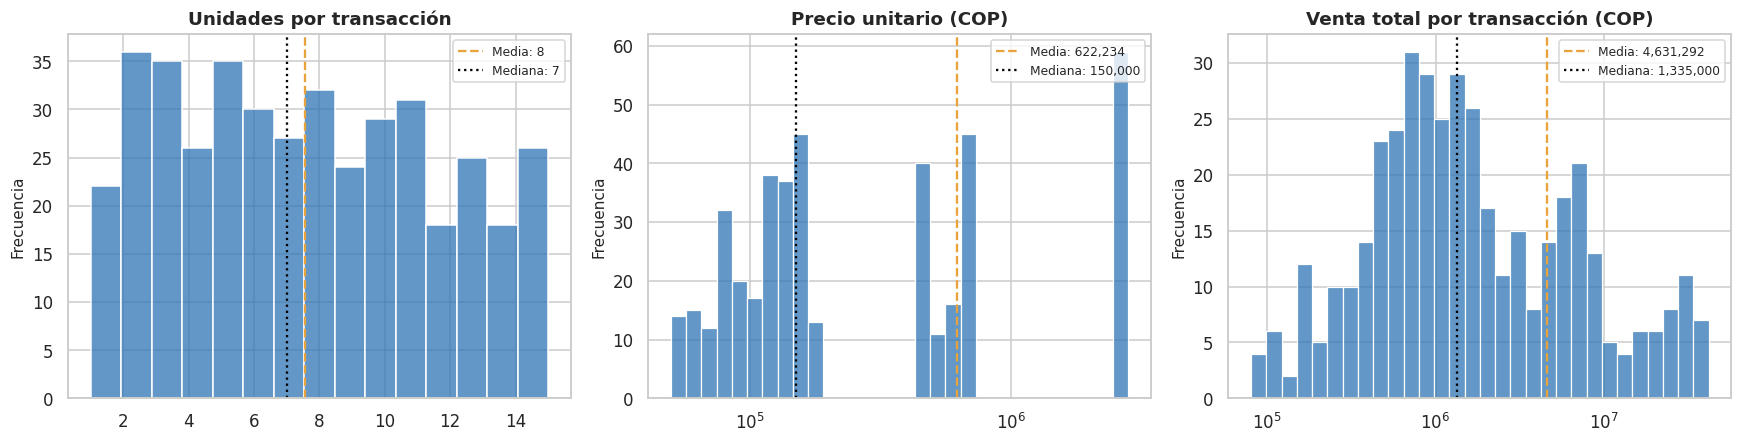

In [25]:
fig, ejes = plt.subplots(1, 3, figsize=(16, 4.2))

for ax, col, titulo in zip(ejes, ["Unidades", "PrecioUnitario", "VentaTotal"], ["Unidades por transacción", "Precio unitario (COP)", "Venta total por transacción (COP)"]):
    if col == "Unidades":
        sns.histplot(df[col], bins=15, color=AZUL, ax=ax)
    else:
        sns.histplot(df[col], bins=30, color=AZUL, ax=ax, log_scale=True)
    ax.axvline(df[col].mean(), color=NARANJA, linestyle="--", label=f"Media: {df[col].mean():,.0f}")
    ax.axvline(df[col].median(), color="black", linestyle=":", label=f"Mediana: {df[col].median():,.0f}")
    ax.set_title(titulo); ax.set_xlabel(""); ax.set_ylabel("Frecuencia"); ax.legend(fontsize=8)

plt.tight_layout(); plt.show()

**Interpretación.** `Unidades` tiene forma casi uniforme. `PrecioUnitario` y `VentaTotal` muestran **varias concentraciones** (picos), reflejo de que cada producto tiene su propio rango de precio. La media (línea naranja) queda por encima de la mediana (línea negra) en ambas, señal de cola a la derecha.

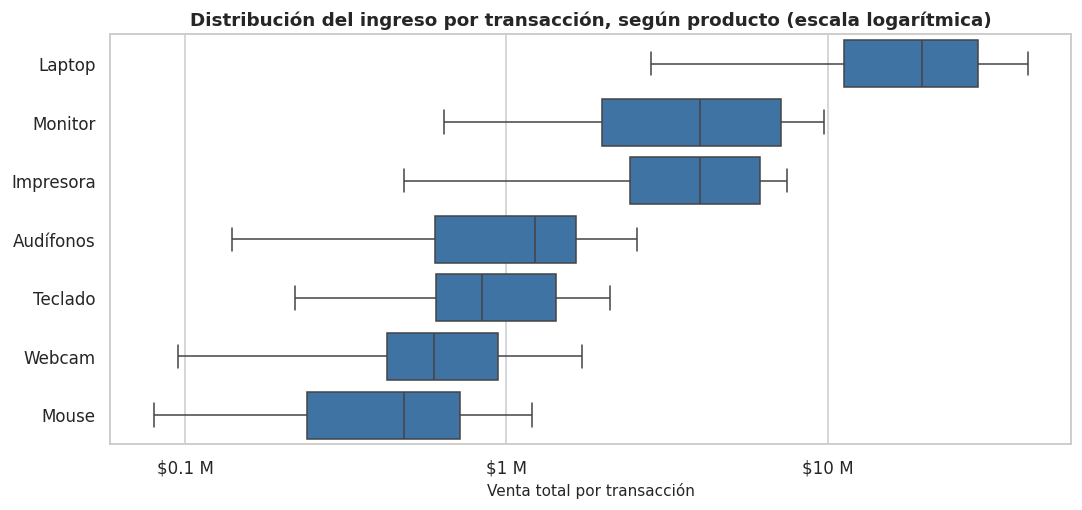

In [26]:
# Dispersión del ingreso por producto
orden = df.groupby("Producto")["VentaTotal"].median().sort_values(ascending=False).index
plt.figure(figsize=(10, 4.8))
sns.boxplot(data=df, y="Producto", x="VentaTotal", order=orden, color=AZUL, fliersize=3)
plt.xscale("log")
plt.gca().xaxis.set_major_formatter(mtick.FuncFormatter(millones))
plt.title("Distribución del ingreso por transacción, según producto (escala logarítmica)")
plt.xlabel("Venta total por transacción"); plt.ylabel("")
plt.tight_layout(); plt.show()

**Interpretación.** El diagrama de caja confirma que el producto explica el nivel de ingreso: las transacciones de **laptop** están en una franja muy por encima de las demás, mientras que mouse, teclado y webcam se concentran en ingresos bajos. Dentro de cada producto la dispersión es moderada: lo que cambia es la cantidad de unidades por transacción.

## Análisis por dimensiones del negocio

Se calculan para cada grupo: transacciones, unidades, ventas totales, **ticket promedio** (ingreso medio por transacción) y **participación** en las ventas.

In [27]:
def resumen_dimension(col):
    g = df.groupby(col).agg(Transacciones=("VentaTotal", "size"), Unidades=("Unidades", "sum"),
                            VentaTotal=("VentaTotal", "sum"), TicketPromedio=("VentaTotal", "mean"))
    g["Participación %"] = 100 * g["VentaTotal"] / g["VentaTotal"].sum()
    return g.sort_values("VentaTotal", ascending=False)

print(f"Ventas totales del periodo: ${df['VentaTotal'].sum():,.0f}  |  Transacciones: {len(df)}  |  Ticket promedio: ${df['VentaTotal'].mean():,.0f}")

Ventas totales del periodo: $1,917,355,000  |  Transacciones: 414  |  Ticket promedio: $4,631,292


### Ventas por producto y diagrama de Pareto

,Transacciones,Unidades,VentaTotal,TicketPromedio,Participación %,Acumulado %
Producto,,,,,,
Laptop,59,435,1220920000,"20,693,559.32",63.68,63.68
Monitor,61,424,276810000,"4,537,868.85",14.44,78.11
Impresora,51,432,209350000,"4,104,901.96",10.92,89.03
Audífonos,70,550,85200000,"1,217,142.86",4.44,93.48
Teclado,51,401,50820000,"996,470.59",2.65,96.13
Webcam,65,463,46475000,"715,000.00",2.42,98.55
Mouse,57,428,27780000,"487,368.42",1.45,100.00


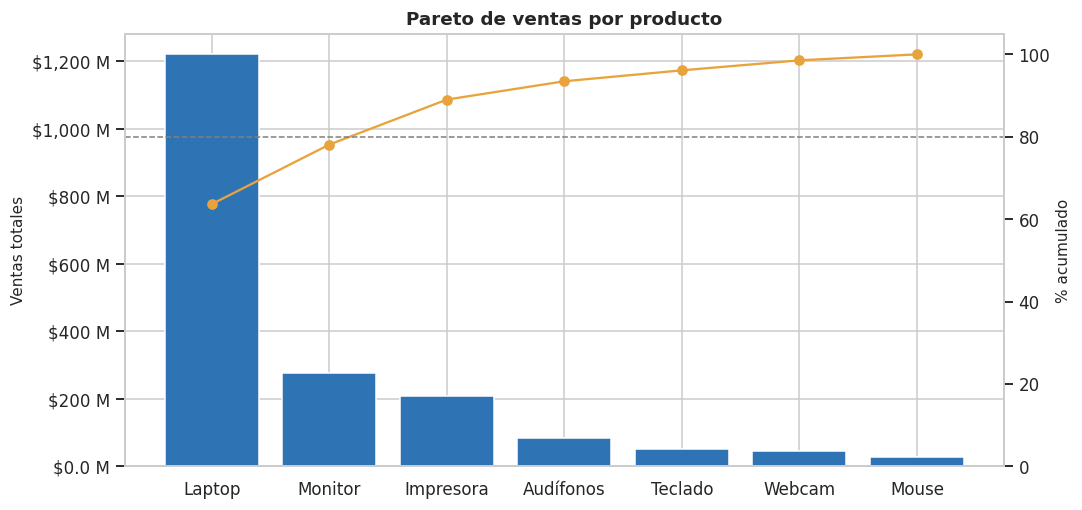

In [28]:
prod = resumen_dimension("Producto")
prod["Acumulado %"] = prod["Participación %"].cumsum()
display(prod)

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.bar(prod.index, prod["VentaTotal"], color=AZUL)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(millones)); ax.set_ylabel("Ventas totales")
ax2 = ax.twinx()
ax2.plot(prod.index, prod["Acumulado %"], color=NARANJA, marker="o")
ax2.axhline(80, color=GRIS, linestyle="--", linewidth=1); ax2.set_ylim(0, 105); ax2.set_ylabel("% acumulado"); ax2.grid(False)
ax.set_title("Pareto de ventas por producto"); plt.tight_layout(); plt.show()

**Interpretación.** **Laptop concentra el 63,7 % de los ingresos** ($1.220,9 millones) con solo el 14,3 % de las transacciones. Tres productos (laptop, monitor e impresora) suman el **89 %** de las ventas, mientras que mouse, teclado y webcam aportan juntos apenas el 6,5 %. Hay una fuerte dependencia de un solo producto: el comportamiento de las laptops determina el resultado de la empresa.

###  Ventas por región

,Transacciones,Unidades,VentaTotal,TicketPromedio,Participación %
Region,,,,,
Barranquilla,72,596,480365000,"6,671,736.11",25.05
Bucaramanga,71,569,390675000,"5,502,464.79",20.38
Cali,79,557,338520000,"4,285,063.29",17.66
Medellín,64,483,265825000,"4,153,515.62",13.86
Pereira,72,556,252635000,"3,508,819.44",13.18
Bogotá,56,372,189335000,"3,380,982.14",9.87


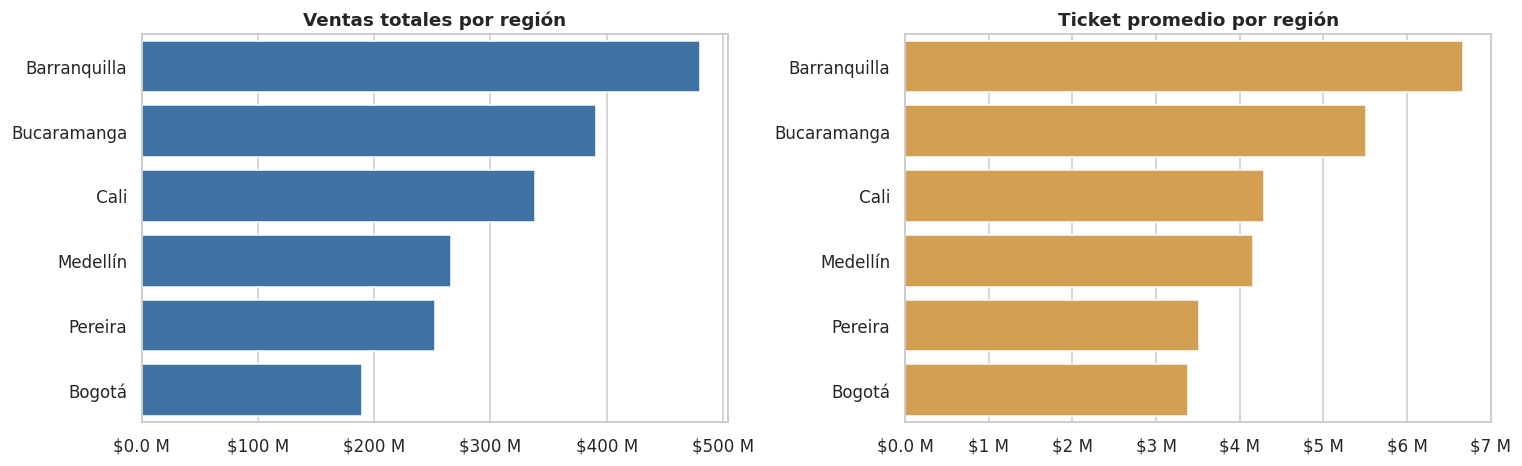

In [29]:
reg = resumen_dimension("Region")
display(reg)

fig, ejes = plt.subplots(1, 2, figsize=(14, 4.4))
sns.barplot(x=reg["VentaTotal"], y=reg.index, color=AZUL, ax=ejes[0])
ejes[0].xaxis.set_major_formatter(mtick.FuncFormatter(millones)); ejes[0].set_title("Ventas totales por región"); ejes[0].set_xlabel(""); ejes[0].set_ylabel("")
sns.barplot(x=reg["TicketPromedio"], y=reg.index, color=NARANJA, ax=ejes[1])
ejes[1].xaxis.set_major_formatter(mtick.FuncFormatter(millones)); ejes[1].set_title("Ticket promedio por región"); ejes[1].set_xlabel(""); ejes[1].set_ylabel("")
plt.tight_layout(); plt.show()

**Interpretación.** **Barranquilla lidera** con $480,4 millones (25,1 %), seguida de Bucaramanga (20,4 %) y Cali (17,7 %). **Bogotá es la región con menores ventas** ($189,3 millones; 9,9 %), con menos transacciones (56) y el ticket promedio más bajo ($3,38 millones). La diferencia entre regiones se explica sobre todo por las laptops: en Barranquilla suman $351,2 millones (73,1 % de su venta), frente a $109,5 millones en Bogotá.

###  Ventas por vendedor

,Transacciones,Unidades,VentaTotal,TicketPromedio,Participación %
Vendedor,,,,,
Diana Gómez,72,553,444030000,"6,167,083.33",23.16
Luis Peña,76,627,392660000,"5,166,578.95",20.48
Ana Torres,60,449,323975000,"5,399,583.33",16.90
Carlos Ruiz,58,446,272615000,"4,700,258.62",14.22
Jorge Salas,69,545,244830000,"3,548,260.87",12.77
Sofía Reyes,79,513,239245000,"3,028,417.72",12.48


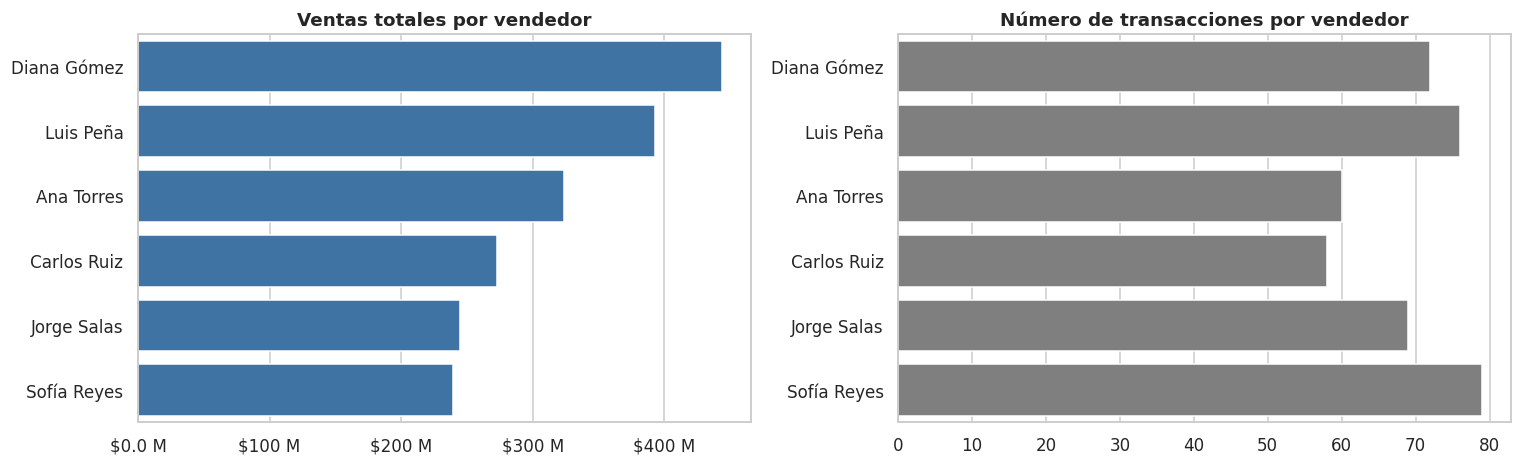

In [30]:
ven = resumen_dimension("Vendedor")
display(ven)

fig, ejes = plt.subplots(1, 2, figsize=(14, 4.4))
sns.barplot(x=ven["VentaTotal"], y=ven.index, color=AZUL, ax=ejes[0])
ejes[0].xaxis.set_major_formatter(mtick.FuncFormatter(millones)); ejes[0].set_title("Ventas totales por vendedor"); ejes[0].set_xlabel(""); ejes[0].set_ylabel("")
sns.barplot(x=ven["Transacciones"], y=ven.index, color=GRIS, ax=ejes[1])
ejes[1].set_title("Número de transacciones por vendedor"); ejes[1].set_xlabel(""); ejes[1].set_ylabel("")
plt.tight_layout(); plt.show()

**Interpretación.** **Diana Gómez** lidera en ingresos ($444,0 millones; 23,2 %) con un ticket promedio de $6,17 millones: el 73,3 % de lo que vende son laptops. **Sofía Reyes** realiza más transacciones (79) pero tiene el ticket más bajo ($3,03 millones) y es la última en ingresos (12,5 %): vende mucho volumen de productos de menor valor. Cuántas ventas se cierran no equivale a cuánto se factura.

### Cruce región × producto

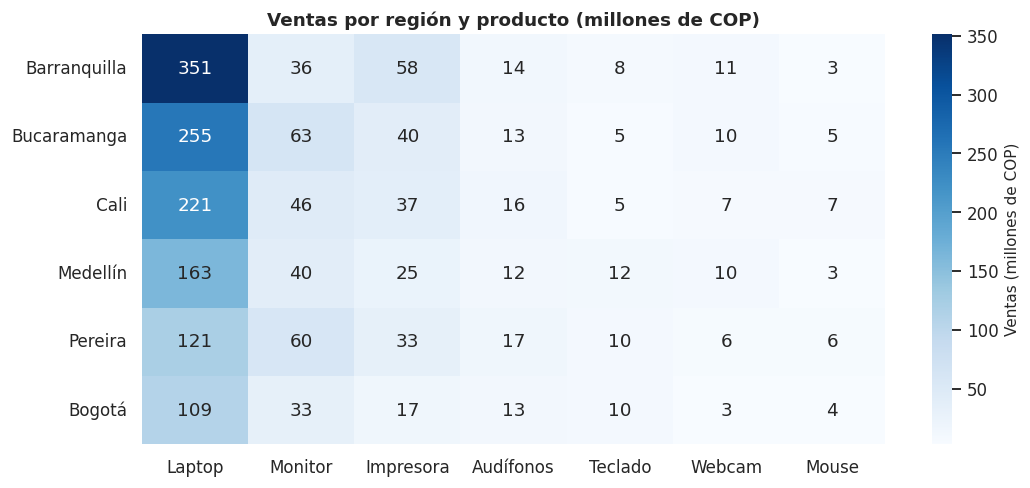

In [31]:
cruce = df.pivot_table(index="Region", columns="Producto", values="VentaTotal", aggfunc="sum", fill_value=0) / 1e6
cruce = cruce.loc[reg.index, prod.index]

plt.figure(figsize=(10, 4.6))
sns.heatmap(cruce, annot=True, fmt=",.0f", cmap="Blues", cbar_kws={"label": "Ventas (millones de COP)"})
plt.title("Ventas por región y producto (millones de COP)"); plt.xlabel(""); plt.ylabel("")
plt.tight_layout(); plt.show()

**Interpretación.** El mapa de calor muestra que la columna de **laptop** domina en todas las regiones. La brecha de Bogotá frente a Barranquilla se concentra en **laptops** ($109,5 frente a $351,2 millones) e **impresoras** ($16,6 frente a $57,5 millones), mientras que en monitores vende casi lo mismo ($33,4 frente a $35,6 millones). Los accesorios (mouse, teclado, webcam y audífonos) aportan poco en todas las regiones, entre $2,6 y $16,9 millones por producto.

##  Tendencia en el tiempo

###  Ventas mensuales y media móvil

Se agrupan las ventas por mes y se calcula una **media móvil de 3 meses** para suavizar la variación y ver la tendencia de fondo.

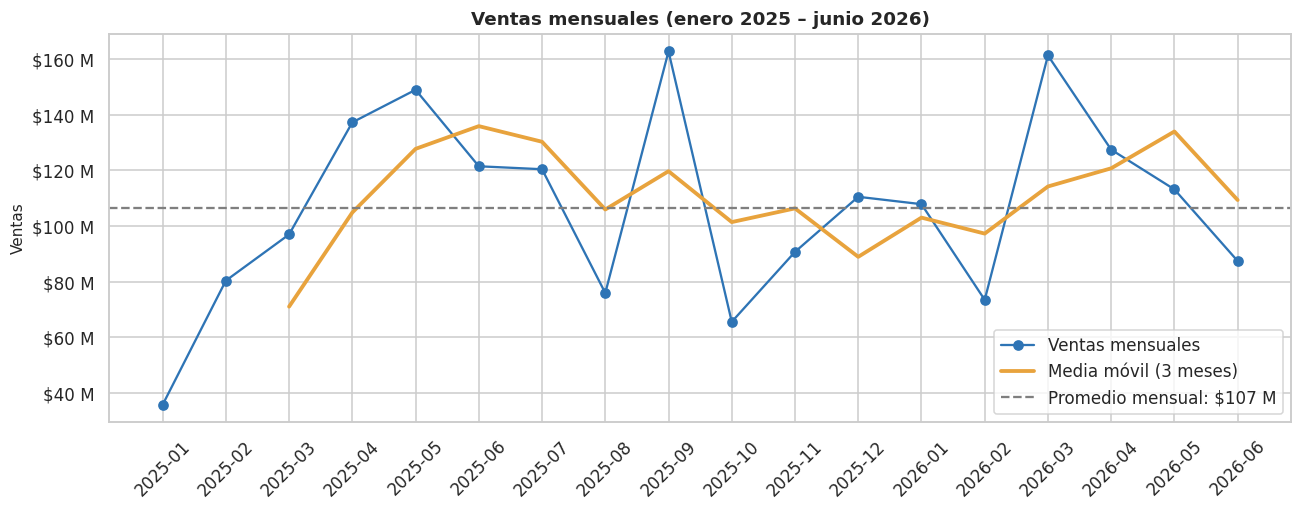

Promedio mensual: $106,519,722  |  Desviación: $34,191,182  |  Coef. de variación: 0.32
Mes con mayores ventas: 2025-09 ($162,675,000)
Mes con menores ventas: 2025-01 ($35,850,000)


In [32]:
mensual = df.groupby("Periodo")["VentaTotal"].sum().to_frame("VentaTotal")
mensual["Media móvil 3m"] = mensual["VentaTotal"].rolling(3).mean()
mensual["Variación mensual %"] = mensual["VentaTotal"].pct_change() * 100

fig, ax = plt.subplots(figsize=(12, 4.8))
ax.plot(mensual.index, mensual["VentaTotal"], marker="o", color=AZUL, label="Ventas mensuales")
ax.plot(mensual.index, mensual["Media móvil 3m"], color=NARANJA, linewidth=2.5, label="Media móvil (3 meses)")
ax.axhline(mensual["VentaTotal"].mean(), color=GRIS, linestyle="--", label=f"Promedio mensual: {millones(mensual['VentaTotal'].mean())}")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(millones)); ax.set_title("Ventas mensuales (enero 2025 – junio 2026)")
ax.set_xlabel(""); ax.set_ylabel("Ventas"); plt.xticks(rotation=45); ax.legend()
plt.tight_layout(); plt.show()

print(f"Promedio mensual: ${mensual['VentaTotal'].mean():,.0f}  |  Desviación: ${mensual['VentaTotal'].std():,.0f}  |  Coef. de variación: {mensual['VentaTotal'].std()/mensual['VentaTotal'].mean():.2f}")
print(f"Mes con mayores ventas: {mensual['VentaTotal'].idxmax()} (${mensual['VentaTotal'].max():,.0f})")
print(f"Mes con menores ventas: {mensual['VentaTotal'].idxmin()} (${mensual['VentaTotal'].min():,.0f})")

**Interpretación.** Las ventas promedian **$106,5 millones al mes**, pero oscilan bastante (coeficiente de variación 0,32). El mes más alto fue **septiembre de 2025** ($162,7 millones) y el más bajo **enero de 2025** ($35,9 millones). La media móvil muestra un aumento en el primer semestre de 2025 y, desde entonces, una **meseta con fluctuaciones** (desde mediados de 2025 la media móvil se mueve entre $89 y $136 millones), sin una tendencia sostenida al alza en 2026.

###  Crecimiento mensual

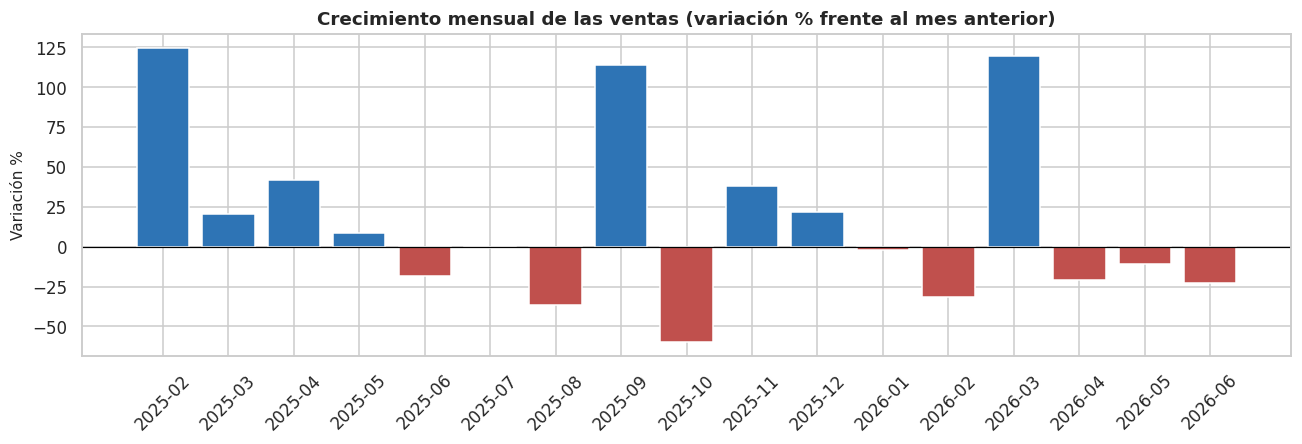

Meses con crecimiento: 8  |  Meses con caída: 9


In [33]:
fig, ax = plt.subplots(figsize=(12, 4.2))
valores = mensual["Variación mensual %"].dropna()
ax.bar(valores.index, valores, color=[AZUL if v >= 0 else "#C0504D" for v in valores])
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Crecimiento mensual de las ventas (variación % frente al mes anterior)")
ax.set_ylabel("Variación %"); ax.set_xlabel(""); plt.xticks(rotation=45)
plt.tight_layout(); plt.show()

print(f"Meses con crecimiento: {(valores > 0).sum()}  |  Meses con caída: {(valores < 0).sum()}")

**Interpretación.** El crecimiento mensual es **muy volátil**: hay aumentos superiores al 100 % (febrero y septiembre de 2025, marzo de 2026) y caídas de hasta −60 % (octubre de 2025). Oscilaciones de ese tamaño sugieren que el resultado de cada mes depende de pocas ventas grandes; el siguiente cálculo lo contrasta con las ventas de laptops.

In [34]:
laptop_mes = df[df["Producto"] == "Laptop"].groupby("Periodo")["VentaTotal"].sum().reindex(mensual.index).fillna(0)
print(f"Correlación entre las ventas mensuales totales y las ventas mensuales de laptops: {mensual['VentaTotal'].corr(laptop_mes):.2f}")
print(f"Participación de las laptops en septiembre de 2025 (mes más alto): {laptop_mes['2025-09'] / mensual.loc['2025-09', 'VentaTotal']:.1%}")
print(f"Participación de las laptops en enero de 2025 (mes más bajo): {laptop_mes['2025-01'] / mensual.loc['2025-01', 'VentaTotal']:.1%}")

Correlación entre las ventas mensuales totales y las ventas mensuales de laptops: 0.90
Participación de las laptops en septiembre de 2025 (mes más alto): 81.1%
Participación de las laptops en enero de 2025 (mes más bajo): 0.0%


**Lectura.** La correlación de 0,90 indica que **los meses buenos y malos dependen casi por completo de las ventas de laptops**: en septiembre de 2025 representaron el 81,1 % del mes y en enero de 2025, el mes más bajo, no hubo ninguna venta de laptops.

### Comparación interanual del primer semestre (2025 frente a 2026)

Para comparar periodos equivalentes se usan los meses de enero a junio de ambos años.

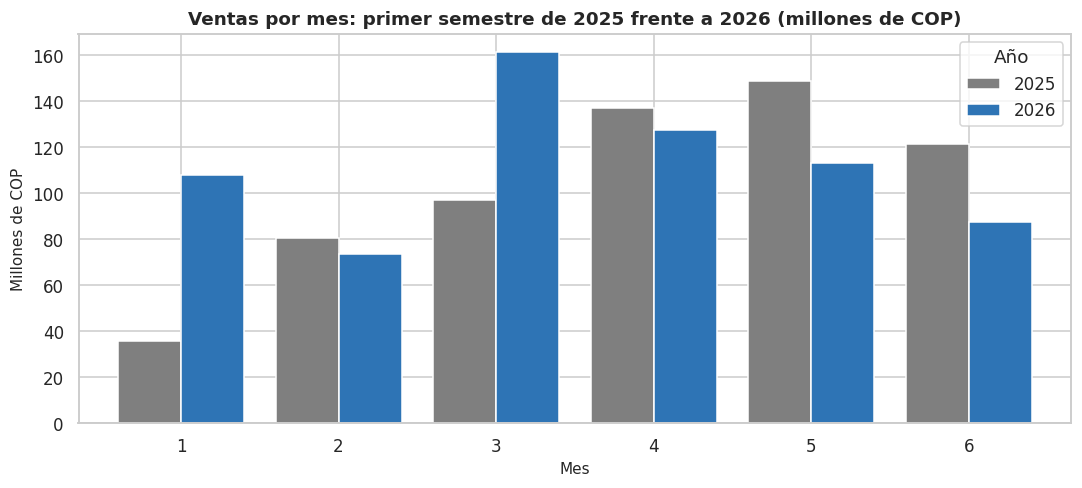

Primer semestre 2025: $620,825,000  |  Primer semestre 2026: $670,635,000  |  Variación: +8.0%

Comparación por trimestre (millones de COP):


Anio,2025,2026,Variación %
Trim,,,
T1 (ene-mar),213.25,342.61,60.66
T2 (abr-jun),407.58,328.03,-19.52



Variación por producto (primer semestre):


Anio,2025,2026,Variación %
Producto,,,
Impresora,46.98,82.83,76.31
Laptop,390.58,429.20,9.89
Monitor,98.32,98.15,-0.17
Audífonos,34.59,26.79,-22.55
Webcam,17.54,12.47,-28.86
Mouse,12.12,8.45,-30.28
Teclado,20.70,12.74,-38.45



Variación por región (primer semestre):


Anio,2025,2026,Variación %
Region,,,
Bogotá,50.66,88.25,74.22
Bucaramanga,107.21,139.08,29.73
Cali,98.92,123.09,24.44
Barranquilla,144.84,176.88,22.12
Medellín,112.61,110.05,-2.28
Pereira,106.58,33.28,-68.77


In [35]:
semestre = df[df["Mes"] <= 6]
comp = semestre.pivot_table(index="Mes", columns="Anio", values="VentaTotal", aggfunc="sum") / 1e6

ax = comp.plot(kind="bar", figsize=(10, 4.6), color=[GRIS, AZUL], width=0.8)
ax.set_title("Ventas por mes: primer semestre de 2025 frente a 2026 (millones de COP)")
ax.set_xlabel("Mes"); ax.set_ylabel("Millones de COP"); plt.xticks(rotation=0); plt.legend(title="Año")
plt.tight_layout(); plt.show()

tot = comp.sum()
print(f"Primer semestre 2025: ${tot[2025]*1e6:,.0f}  |  Primer semestre 2026: ${tot[2026]*1e6:,.0f}  |  Variación: {(tot[2026]/tot[2025]-1):+.1%}")

print("\nComparación por trimestre (millones de COP):")
trim = semestre.assign(Trim=np.where(semestre["Mes"] <= 3, "T1 (ene-mar)", "T2 (abr-jun)")).pivot_table(index="Trim", columns="Anio", values="VentaTotal", aggfunc="sum") / 1e6
trim["Variación %"] = (trim[2026] / trim[2025] - 1) * 100
display(trim)

print("\nVariación por producto (primer semestre):")
por_prod = semestre.pivot_table(index="Producto", columns="Anio", values="VentaTotal", aggfunc="sum") / 1e6
por_prod["Variación %"] = (por_prod[2026] / por_prod[2025] - 1) * 100
display(por_prod.sort_values("Variación %", ascending=False))

print("\nVariación por región (primer semestre):")
por_reg = semestre.pivot_table(index="Region", columns="Anio", values="VentaTotal", aggfunc="sum") / 1e6
por_reg["Variación %"] = (por_reg[2026] / por_reg[2025] - 1) * 100
display(por_reg.sort_values("Variación %", ascending=False))

**Interpretación.** El primer semestre de 2026 vendió **$670,6 millones frente a $620,8 millones** en 2025: un **crecimiento de 8,0 %**. Detrás de la cifra total hay movimientos opuestos:

- **Por trimestre:** el crecimiento se concentra en el **primer trimestre (+60,7 %)**; el **segundo trimestre de 2026 quedó 19,5 % por debajo** del de 2025, con caídas en abril, mayo y junio (el gráfico lo muestra: solo enero y marzo superan al año anterior).
- **Por producto:** crecieron la **impresora (+76,3 %)** y la **laptop (+9,9 %)**; el monitor se mantuvo (−0,2 %); y los accesorios **cayeron** (audífonos −22,5 %, webcam −28,9 %, mouse −30,3 % y teclado −38,5 %).
- **Por región:** crecieron Bogotá (+74,2 %), Bucaramanga (+29,7 %), Cali (+24,4 %) y Barranquilla (+22,1 %); Medellín se mantuvo (−2,3 %) y **Pereira cayó −68,8 %**, de $106,6 a $33,3 millones. Pereira merece una revisión específica.

###  Cambios de precio año contra año

In [36]:
precio = df.pivot_table(index="Producto", columns="Anio", values="PrecioUnitario", aggfunc="mean")
precio["Variación %"] = (precio[2026] / precio[2025] - 1) * 100
display(precio.sort_values("Variación %"))

Anio,2025,2026,Variación %
Producto,,,
Webcam,"100,333.33","99,000.00",-1.33
Audífonos,"154,489.80","153,333.33",-0.75
Monitor,"655,000.00","651,200.00",-0.58
Laptop,"2,806,578.95","2,807,619.05",0.04
Impresora,"483,448.28","485,909.09",0.51
Teclado,"125,675.68","126,428.57",0.60
Mouse,"65,116.28","65,714.29",0.92


**Interpretación.** Los precios promedio **prácticamente no cambian** de 2025 a 2026: las variaciones están entre −1,3 % (webcam) y +0,9 % (mouse), y la laptop se mantiene en torno a $2,8 millones. Por tanto, el crecimiento del semestre no se explica por cambios de precio, sino por el **volumen y la mezcla de productos vendidos**.

## Relaciones entre variables

La **correlación de Pearson** mide la relación lineal entre dos variables (de −1 a 1); la de **Spearman**, la relación de orden, menos sensible a valores extremos. Se calculan ambas entre `Unidades`, `PrecioUnitario` y `VentaTotal`.

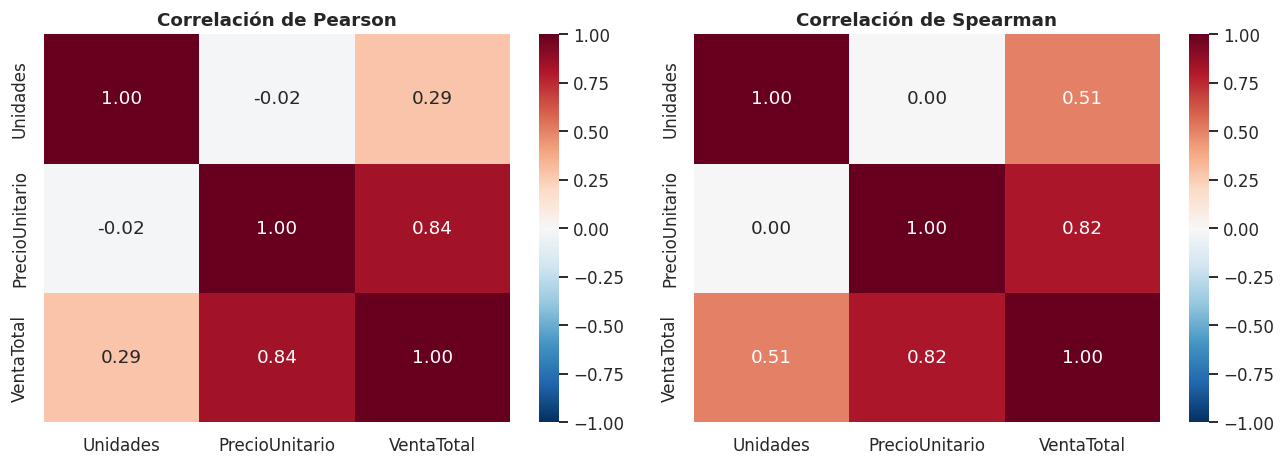

In [37]:
variables = ["Unidades", "PrecioUnitario", "VentaTotal"]
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.4))
for ax, metodo in zip(ejes, ["pearson", "spearman"]):
    sns.heatmap(df[variables].corr(method=metodo), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
    ax.set_title(f"Correlación de {metodo.capitalize()}")
plt.tight_layout(); plt.show()

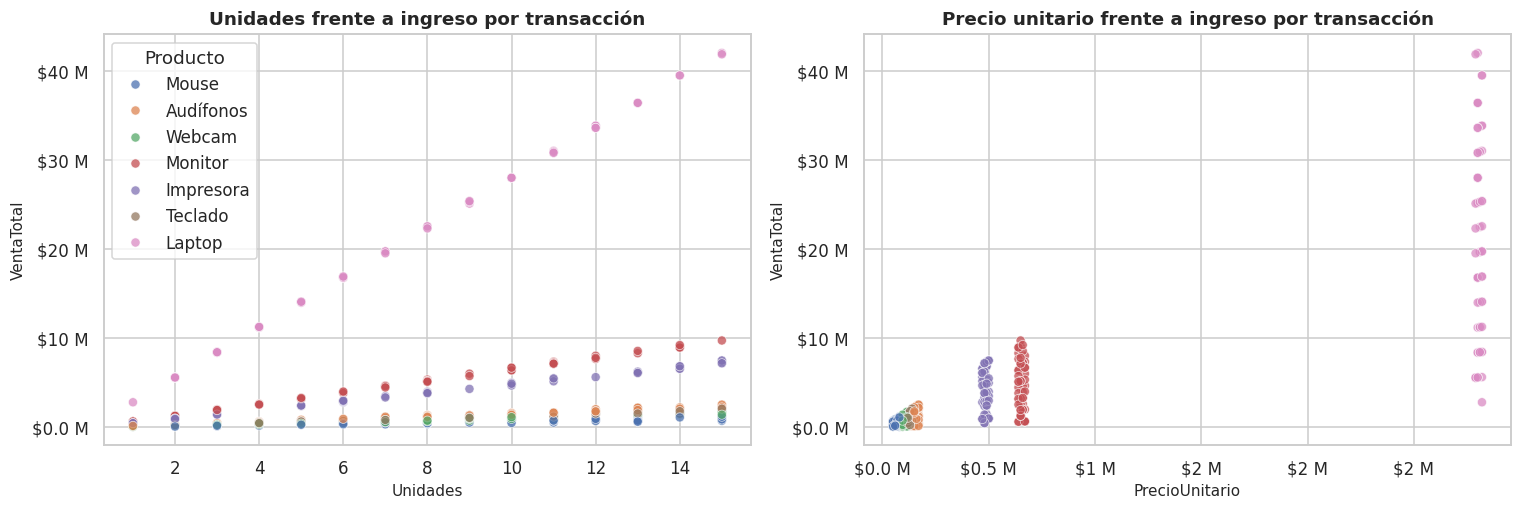

In [38]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 4.8))
sns.scatterplot(data=df, x="Unidades", y="VentaTotal", hue="Producto", alpha=0.75, ax=ejes[0])
ejes[0].yaxis.set_major_formatter(mtick.FuncFormatter(millones)); ejes[0].set_title("Unidades frente a ingreso por transacción")
sns.scatterplot(data=df, x="PrecioUnitario", y="VentaTotal", hue="Producto", alpha=0.75, ax=ejes[1], legend=False)
ejes[1].xaxis.set_major_formatter(mtick.FuncFormatter(millones)); ejes[1].yaxis.set_major_formatter(mtick.FuncFormatter(millones))
ejes[1].set_title("Precio unitario frente a ingreso por transacción")
plt.tight_layout(); plt.show()

**Interpretación.**

- **Precio y venta total:** correlación fuerte (Pearson 0,84; Spearman 0,82). El ingreso de una transacción depende sobre todo del precio del producto.
- **Unidades y venta total:** relación positiva pero moderada (Pearson 0,29; Spearman 0,51): vender más unidades ayuda, pero pesa mucho menos que el producto vendido.
- **Unidades y precio:** prácticamente nula (−0,02): no se compran más unidades de productos baratos ni menos de caros; la cantidad es independiente del precio.
- En el gráfico de dispersión se aprecian **bandas horizontales por producto**: dentro de cada producto el ingreso crece con las unidades, pero las bandas están separadas por el precio.

*Nota:* una correlación describe asociación, no causalidad.

## Hallazgos principales

In [39]:
total = df["VentaTotal"].sum()
print("INDICADORES CLAVE")
print(f"· Ventas totales: ${total:,.0f} en {len(df)} transacciones ({df['Fecha'].min():%b %Y} – {df['Fecha'].max():%b %Y})")
print(f"· Ticket promedio: ${df['VentaTotal'].mean():,.0f}  |  Ticket mediano: ${df['VentaTotal'].median():,.0f}")
print(f"· Producto líder: {prod.index[0]} ({prod['Participación %'].iloc[0]:.1f} % de las ventas)")
print(f"· Región líder: {reg.index[0]} ({reg['Participación %'].iloc[0]:.1f} %)  |  Región con menor venta: {reg.index[-1]} ({reg['Participación %'].iloc[-1]:.1f} %)")
print(f"· Vendedor líder: {ven.index[0]} ({ven['Participación %'].iloc[0]:.1f} %)")
print(f"· Promedio mensual: ${mensual['VentaTotal'].mean():,.0f}")
print(f"· Variación interanual del primer semestre: {(tot[2026]/tot[2025]-1):+.1%}")

INDICADORES CLAVE
· Ventas totales: $1,917,355,000 en 414 transacciones (Jan 2025 – Jun 2026)
· Ticket promedio: $4,631,292  |  Ticket mediano: $1,335,000
· Producto líder: Laptop (63.7 % de las ventas)
· Región líder: Barranquilla (25.1 %)  |  Región con menor venta: Bogotá (9.9 %)
· Vendedor líder: Diana Gómez (23.2 %)
· Promedio mensual: $106,519,722
· Variación interanual del primer semestre: +8.0%


1. **Las ventas suman $1.917,4 millones** en 18 meses (414 transacciones), con un ticket promedio de $4,63 millones y un ticket mediano de $1,34 millones.
2. **Hay una fuerte concentración en un producto:** las laptops generan el 63,7 % de los ingresos con el 14,3 % de las transacciones, y tres productos suman el 89 %.
3. **La distribución del ingreso es muy asimétrica** (asimetría 2,77; coeficiente de variación 1,73): 42 transacciones atípicas, todas de laptops, explican el 56,8 % de los ingresos.
4. **Número de transacciones y valor vendido no coinciden:** Sofía Reyes cierra más ventas (79) pero factura menos (12,5 %); Diana Gómez lidera en ingresos (23,2 %) con 72 transacciones.
5. **Barranquilla es la región líder (25,1 %) y Bogotá la de menores ventas (9,9 %)**; la diferencia se explica sobre todo por las laptops.
6. **La evolución mensual es volátil** y depende de las laptops (correlación de 0,90 entre las ventas mensuales totales y las de laptops).
7. **El primer semestre de 2026 creció 8,0 %** frente a 2025, pero el crecimiento se concentra en el primer trimestre (+60,7 %): el **segundo trimestre cayó 19,5 %**. Crecieron las impresoras y las laptops; los accesorios cayeron entre −22 % y −39 %, y **Pereira cayó −68,8 %**.
8. **Los precios no cambiaron** (variaciones entre −1,3 % y +0,9 %): el crecimiento viene del volumen y de la mezcla de productos.
9. **El precio del producto determina el ingreso** (correlación 0,84), mucho más que las unidades (0,29).

## Conclusiones, recomendaciones y limitaciones

**Conclusiones**

- El análisis descriptivo permitió pasar de un archivo con errores a una **descripción clara del negocio**: qué se vende (laptops, sobre todo), dónde (Barranquilla, Bucaramanga y Cali), quién (Diana Gómez, Luis Peña y Ana Torres) y cómo evoluciona (con alta volatilidad y un crecimiento de 8,0 % en el primer semestre, que se concentra en el primer trimestre: el segundo trimestre de 2026 cayó 19,5 % frente al de 2025).
- El principal riesgo que revelan los datos es la **dependencia de un solo producto**: los resultados mensuales suben o bajan según las ventas de laptops.
- La **media** describe mal estos datos por su asimetría; la **mediana** y el análisis por grupos son más fiables.

**Recomendaciones para la gestión** (derivadas de los hallazgos, a validar con información adicional)

1. **Reducir la dependencia de las laptops:** impulsar impresoras (que crecieron 76,3 %) y monitores, y revisar la caída de los accesorios.
2. **Revisar el caso de Pereira** (−68,8 % en el primer semestre) y la **caída del segundo trimestre de 2026** (−19,5 %) con el equipo comercial para entender qué cambió.
3. **Analizar la brecha de Bogotá** frente a Barranquilla en laptops y evaluar si hay una oportunidad de crecimiento.
4. **Evaluar el desempeño de los vendedores por valor y no solo por número de ventas**, usando el ticket promedio y el ingreso.
5. **Planificar inventario y metas mensuales con la volatilidad en mente**, porque un mes sin ventas grandes de laptops reduce los ingresos de forma drástica.

**Limitaciones**

- Es un conjunto de datos **de ejemplo** y de **18 meses**: no permite analizar estacionalidad anual.
- No incluye costos, márgenes ni datos de clientes, por lo que no se puede hablar de rentabilidad.
- Es un análisis **descriptivo**: identifica patrones, pero no explica sus causas ni predice. Los siguientes pasos serían un análisis diagnóstico (por qué cayó Pereira) y predictivo (pronóstico de ventas).
- El primer mes (enero de 2025) podría reflejar un registro parcial.

## Publicación del trabajo

> **Enlace al repositorio (GitHub o Google Drive):** **[pegar aquí el enlace una vez publicado]**

**Pasos para publicar en GitHub**

1. Crear un repositorio nuevo (público, o con acceso para el docente).
2. Subir este notebook (`.ipynb`), el archivo `ventas_ejemplo.csv` y, opcionalmente, `ventas_limpias.csv` y el `README.md`.
3. Verificar que el notebook se abre desde el enlace y que el archivo de datos está en la misma carpeta.
4. Copiar el enlace del repositorio, pegarlo en la primera celda de este notebook y entregarlo en la plataforma junto con el archivo `.ipynb`.

**Opción con Google Drive:** subir los mismos archivos a una carpeta, compartirla con acceso de lectura para cualquier persona con el enlace y pegar el enlace.

## Referencias

- Harvard Business School Online. (s. f.). *What is descriptive analytics? 5 examples*. https://online.hbs.edu/blog/post/descriptive-analytics

- Repositorio Github: https://github.com/JeisonM025/BUSINESS-ANALYTICS-BA-.git